In [1]:
!pip install -q stable-baselines3 gymnasium
import gymnasium as gym, numpy as np, pandas as pd, time
from stable_baselines3 import PPO
print("Ready")

Ready


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [2]:
def evaluate(policy_fn, env_id, n=20, seed=0):
    """Average total reward over n episodes for a policy mapping observation -> action."""
    env = gym.make(env_id); returns = []
    for i in range(n):
        obs, _ = env.reset(seed=seed + i); done, total = False, 0.0
        while not done:
            obs, r, term, trunc, _ = env.step(policy_fn(obs)); total += r; done = term or trunc
        returns.append(total)
    return np.mean(returns), np.std(returns)

TASKS = {"CartPole-v1": 100_000, "Acrobot-v1": 200_000}   # training steps per task
teachers = {}
for env_id, steps in TASKS.items():
    t0 = time.time()
    model = PPO("MlpPolicy", env_id, seed=0, verbose=0).learn(total_timesteps=steps)
    teachers[env_id] = model
    mean, std = evaluate(lambda o: int(model.predict(o, deterministic=True)[0]), env_id)
    print(f"{env_id}: neural teacher return {mean:.1f} ± {std:.1f}  ({time.time() - t0:.0f}s)")

CartPole-v1: neural teacher return 500.0 ± 0.0  (148s)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Acrobot-v1: neural teacher return -83.1 ± 12.3  (297s)


In [3]:
from sklearn.tree import DecisionTreeClassifier, export_text

def collect(env_id, policy_fn, n_episodes, seed):
    """Run a policy and record every state it visits."""
    env = gym.make(env_id); states = []
    for i in range(n_episodes):
        obs, _ = env.reset(seed=seed + i); done = False
        while not done:
            states.append(obs)
            obs, r, term, trunc, _ = env.step(policy_fn(obs)); done = term or trunc
    return np.array(states)

def dagger(env_id, depth, seed, iters=8, eps_per_iter=10):
    teacher = teachers[env_id]
    label = lambda S: teacher.predict(S, deterministic=True)[0]
    X = collect(env_id, lambda o: int(label(o[None])[0]), eps_per_iter, seed * 1000)
    y = label(X)
    tree = DecisionTreeClassifier(max_depth=depth, random_state=seed).fit(X, y)
    for it in range(iters):
        Xn = collect(env_id, lambda o: int(tree.predict(o[None])[0]), eps_per_iter,
                     seed * 1000 + 100 * (it + 1))
        X, y = np.vstack([X, Xn]), np.concatenate([y, label(Xn)])
        tree = DecisionTreeClassifier(max_depth=depth, random_state=seed).fit(X, y)
    return tree

DEPTHS, SEEDS = [1, 2, 3, 4, 6, 8], [0, 1, 2, 3, 4]
rows, trees = [], {}
t0 = time.time()
for env_id in TASKS:
    for depth in DEPTHS:
        for seed in SEEDS:
            tree = dagger(env_id, depth, seed)
            trees[(env_id, depth, seed)] = tree
            mean, _ = evaluate(lambda o: int(tree.predict(o[None])[0]), env_id, n=20, seed=10_000)
            rows.append(dict(task=env_id, depth=depth, seed=seed, ret=mean, leaves=tree.get_n_leaves()))
        d = [r["ret"] for r in rows if r["task"] == env_id and r["depth"] == depth]
        print(f"{env_id} depth {depth}: return {np.mean(d):7.1f} ± {np.std(d):5.1f}  ({time.time() - t0:.0f}s)")

res = pd.DataFrame(rows)

CartPole-v1 depth 1: return    59.6 ±  33.4  (23s)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CartPole-v1 depth 2: return   174.6 ± 167.4  (53s)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CartPole-v1 depth 3: return   290.7 ± 124.5  (98s)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (14 outputs left out)

Acrobot-v1 depth 6: return   -81.3 ±   3.2  (403s)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Acrobot-v1 depth 8: return   -80.4 ±   1.9  (424s)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [4]:
FEATURES = {"CartPole-v1": ["cart_position", "cart_velocity", "pole_angle", "pole_angular_velocity"],
            "Acrobot-v1": ["cos_theta1", "sin_theta1", "cos_theta2", "sin_theta2",
                           "theta1_velocity", "theta2_velocity"]}

for env_id in TASKS:
    # States from the teacher's own behavior, used to compare trees' decisions
    S = collect(env_id, lambda o: int(teachers[env_id].predict(o[None], deterministic=True)[0]), 10, 50_000)
    for depth in [2, 3]:
        preds = np.array([trees[(env_id, depth, s)].predict(S) for s in SEEDS])
        agree = np.mean([(preds[i] == preds[j]).mean() for i in range(5) for j in range(i + 1, 5)])
        roots = [FEATURES[env_id][trees[(env_id, depth, s)].tree_.feature[0]] for s in SEEDS]
        rets = res[(res.task == env_id) & (res.depth == depth)].ret.round(1).tolist()
        print(f"\n{env_id}, depth {depth}: returns by seed {rets}")
        print(f"  root split feature by seed: {roots}")
        print(f"  average action agreement between seeds: {agree:.1%}")
    print(f"\nExample depth-2 tree for {env_id} (seed 0):")
    print(export_text(trees[(env_id, 2, 0)], feature_names=FEATURES[env_id]))

/tmp/ipykernel_3578/447228067.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  S = collect(env_id, lambda o: int(teachers[env_id].predict(o[None], deterministic=True)[0]), 10, 50_000)



CartPole-v1, depth 2: returns by seed [47.4, 497.8, 106.3, 53.3, 168.3]
  root split feature by seed: ['pole_angular_velocity', 'pole_angular_velocity', 'pole_angular_velocity', 'pole_angular_velocity', 'cart_position']
  average action agreement between seeds: 60.9%

CartPole-v1, depth 3: returns by seed [500.0, 269.3, 291.8, 283.6, 108.6]
  root split feature by seed: ['pole_angular_velocity', 'pole_angular_velocity', 'pole_angular_velocity', 'pole_angular_velocity', 'pole_angular_velocity']
  average action agreement between seeds: 74.8%

Example depth-2 tree for CartPole-v1 (seed 0):
|--- pole_angular_velocity <= -0.01
|   |--- pole_angle <= 0.01
|   |   |--- class: 0
|   |--- pole_angle >  0.01
|   |   |--- class: 1
|--- pole_angular_velocity >  -0.01
|   |--- pole_angle <= -0.00
|   |   |--- class: 0
|   |--- pole_angle >  -0.00
|   |   |--- class: 1



/tmp/ipykernel_3578/447228067.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  S = collect(env_id, lambda o: int(teachers[env_id].predict(o[None], deterministic=True)[0]), 10, 50_000)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Acrobot-v1, depth 2: returns by seed [-94.4, -89.4, -81.8, -81.6, -96.2]
  root split feature by seed: ['theta1_velocity', 'theta1_velocity', 'theta1_velocity', 'theta1_velocity', 'theta1_velocity']
  average action agreement between seeds: 98.6%

Acrobot-v1, depth 3: returns by seed [-94.0, -98.2, -83.0, -88.1, -96.2]
  root split feature by seed: ['theta1_velocity', 'theta1_velocity', 'theta1_velocity', 'theta1_velocity', 'theta1_velocity']
  average action agreement between seeds: 99.0%

Example depth-2 tree for Acrobot-v1 (seed 0):
|--- theta1_velocity <= -0.00
|   |--- theta2_velocity <= -2.00
|   |   |--- class: 0
|   |--- theta2_velocity >  -2.00
|   |   |--- class: 2
|--- theta1_velocity >  -0.00
|   |--- theta2_velocity <= 1.76
|   |   |--- class: 0
|   |--- theta2_velocity >  1.76
|   |   |--- class: 2



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [5]:
from sklearn.linear_model import LogisticRegression

def dagger_fit(env_id, make_model, seed, iters=8, eps_per_iter=10):
    """DAgger with any classifier (same procedure as before)."""
    teacher = teachers[env_id]
    label = lambda S: teacher.predict(S, deterministic=True)[0]
    X = collect(env_id, lambda o: int(label(o[None])[0]), eps_per_iter, seed * 1000)
    y = label(X); m = make_model().fit(X, y)
    for it in range(iters):
        Xn = collect(env_id, lambda o: int(m.predict(o[None])[0]), eps_per_iter, seed * 1000 + 100 * (it + 1))
        X, y = np.vstack([X, Xn]), np.concatenate([y, label(Xn)])
        m = make_model().fit(X, y)
    return m

lin_rows = []
for env_id in TASKS:
    for C in [0.001, 0.01, 0.1, 1.0]:                 # smaller C = sparser policy
        for seed in SEEDS:
            m = dagger_fit(env_id, lambda: LogisticRegression(penalty="l1", C=C, solver="saga", max_iter=5000), seed)
            mean, _ = evaluate(lambda o: int(m.predict(o[None])[0]), env_id, n=20, seed=10_000)
            nnz = int((np.abs(m.coef_).sum(0) > 1e-6).sum())
            lin_rows.append(dict(task=env_id, C=C, seed=seed, ret=mean, features_used=nnz))
        d = pd.DataFrame(lin_rows); d = d[(d.task == env_id) & (d.C == C)]
        print(f"{env_id} C={C}: return {d.ret.mean():7.1f} ± {d.ret.std():5.1f}, "
              f"features used {d.features_used.mean():.1f}")
    best = m  # last model, for inspection
    print(f"  Example weights (C=1.0, seed 4): ", dict(zip(FEATURES[env_id], np.round(best.coef_[0], 3))))

CartPole-v1 C=0.001: return     9.4 ±   0.0, features used 0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CartPole-v1 C=0.01: return   500.0 ±   0.0, features used 4.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CartPole-v1 C=0.1: return   500.0 ±   0.0, features used 4.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (6 outputs left out)

Acrobot-v1 C=0.1: return   -79.0 ±   0.5, features used 5.2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Acrobot-v1 C=1.0: return   -78.3 ±   0.6, features used 6.0
  Example weights (C=1.0, seed 4):  {'cos_theta1': np.float32(0.0), 'sin_theta1': np.float32(-9.59), 'cos_theta2': np.float32(1.767), 'sin_theta2': np.float32(3.489), 'theta1_velocity': np.float32(3.707), 'theta2_velocity': np.float32(-7.226)}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [7]:
import warnings
warnings.filterwarnings("ignore")
from itertools import combinations
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

# (a) CartPole: which PAIRS of features are enough for a linear policy?
print("CartPole: linear policies using only 2 features")
for cols in combinations(range(4), 2):
    make = lambda c=cols: make_pipeline(FunctionTransformer(lambda X, c=c: X[:, list(c)]),
                                        LogisticRegression(max_iter=5000))
    rets = []
    for seed in SEEDS:
        m = dagger_fit("CartPole-v1", make, seed)
        rets.append(evaluate(lambda o: int(m.predict(o[None])[0]), "CartPole-v1", n=20, seed=10_000)[0])
    names = " + ".join(FEATURES["CartPole-v1"][c] for c in cols)
    print(f"  {names:45s}: {np.mean(rets):6.1f} ± {np.std(rets):5.1f}")

# (b) Acrobot: which 2 features does the sparsest policy use?
m_ac = dagger_fit("Acrobot-v1", lambda: LogisticRegression(penalty="l1", C=0.001, solver="saga", max_iter=5000), 0)
used = np.abs(m_ac.coef_).sum(0) > 1e-6
print("\nAcrobot sparse policy uses:", [f for f, u in zip(FEATURES["Acrobot-v1"], used) if u])
for k, action in enumerate(["torque -1", "torque 0", "torque +1"]):
    print(f"  {action}: " + ", ".join(f"{f} {w:+.3f}" for f, w, u in
                                       zip(FEATURES["Acrobot-v1"], m_ac.coef_[k], used) if u))

# (c) Confirm "student beats teacher" with 100 new episodes
t_mean, t_sd = evaluate(lambda o: int(teachers["Acrobot-v1"].predict(o[None], deterministic=True)[0][0]
                                      if np.ndim(teachers["Acrobot-v1"].predict(o[None], deterministic=True)[0]) else
                                      teachers["Acrobot-v1"].predict(o[None], deterministic=True)[0]),
                        "Acrobot-v1", n=100, seed=20_000)
s_mean, s_sd = evaluate(lambda o: int(m_ac.predict(o[None])[0]), "Acrobot-v1", n=100, seed=20_000)
print(f"\n100 new episodes: teacher {t_mean:.1f} ± {t_sd / 10:.1f} (SE), "
      f"2-feature linear student {s_mean:.1f} ± {s_sd / 10:.1f} (SE)")

CartPole: linear policies using only 2 features
  cart_position + cart_velocity                :   45.8 ±   3.4
  cart_position + pole_angle                   :   45.5 ±   0.3
  cart_position + pole_angular_velocity        :  110.5 ±   3.1
  cart_velocity + pole_angle                   :  321.5 ± 131.2
  cart_velocity + pole_angular_velocity        :  279.2 ±   5.1
  pole_angle + pole_angular_velocity           :  500.0 ±   0.0

Acrobot sparse policy uses: ['theta1_velocity', 'theta2_velocity']
  torque -1: theta1_velocity +0.320, theta2_velocity -0.000
  torque 0: theta1_velocity +0.000, theta2_velocity +0.000
  torque +1: theta1_velocity +0.000, theta2_velocity +1.231

100 new episodes: teacher -81.8 ± 1.4 (SE), 2-feature linear student -78.9 ± 2.3 (SE)


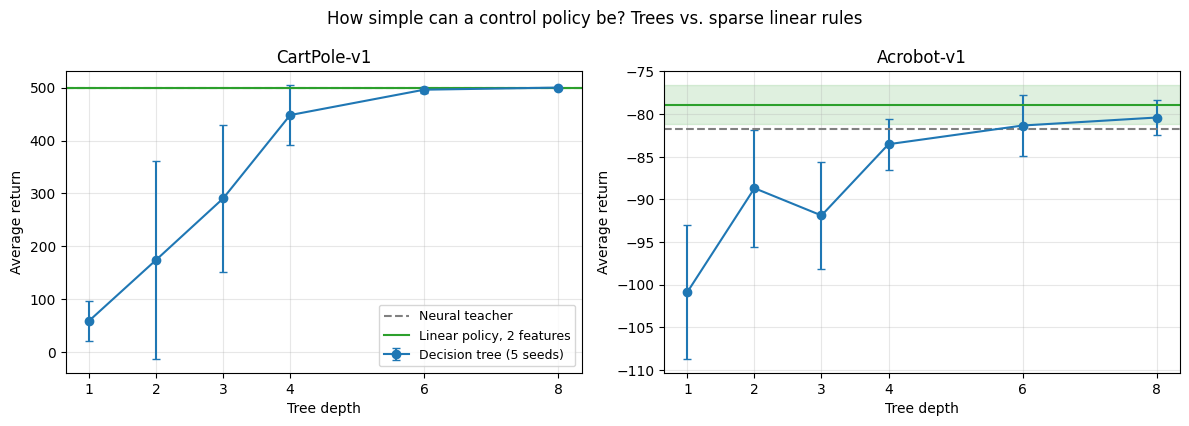

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import matplotlib.pyplot as plt

lin = pd.DataFrame(lin_rows)
acro_lin = lin[(lin.task == "Acrobot-v1") & (lin.C == 0.001)].ret          # 2-feature linear policy
LINEAR_2F = {"CartPole-v1": (500.0, 0.0),                                    # pole angle + angular velocity (Step 4c)
             "Acrobot-v1": (-78.9, 2.3)}
TEACHER = {"CartPole-v1": 500.0, "Acrobot-v1": -81.8}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, env_id in zip(axes, TASKS):
    d = res[res.task == env_id].groupby("depth").ret.agg(["mean", "std"]).loc[DEPTHS]
    ax.errorbar(DEPTHS, d["mean"], yerr=d["std"], marker="o", capsize=3, label="Decision tree (5 seeds)")
    ax.axhline(TEACHER[env_id], color="gray", linestyle="--", label="Neural teacher")
    m, s = LINEAR_2F[env_id]
    ax.axhspan(m - s, m + s, color="C2", alpha=0.15)
    ax.axhline(m, color="C2", label="Linear policy, 2 features")
    ax.set_xlabel("Tree depth"); ax.set_ylabel("Average return"); ax.set_title(env_id)
    ax.set_xticks(DEPTHS); ax.grid(alpha=0.3)
axes[0].legend(fontsize=9, loc="lower right")
plt.suptitle("How simple can a control policy be? Trees vs. sparse linear rules")
plt.tight_layout(); plt.savefig("policy_simplicity.png", dpi=200, bbox_inches="tight"); plt.show()

from google.colab import files
files.download("policy_simplicity.png")